# Figure S21: Gene-level colocalization rates

Gene-level colocalization proportions for each molecular-assay pair.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_INPUT_ROOT` to the
source result tables and `QTL_SUSIE_ROOT` to the separate fine-mapping tables.
Set `QTL_PAPER_ROOT` to the local reference directory and `QTL_SOURCE_ROOT`
to the figure checkout. Set these variables in R before running the cells.
Paths can contain spaces.

Run the cells from top to bottom. The cells show input reads, filters, joins,
counts, models, and plot construction. Intermediate objects stay in this R
session. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Source scripts

The processing steps below follow these preparation scripts. The source data are not included in Git.

- [fig3_coloc](../../preparation/Fig3/build.R): Read FastENLOC result tables, assign per-pair Bayesian FDR calls, join validated variant/gene annotations and strongest posterior representatives, build credible-set components, fit current concordance and MAF-rate models, and derive S20-S23 summaries.

The notebook runs the processing in its own cells. The preparation guide lists the original input requirements and missing inputs.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
input_root <- Sys.getenv("QTL_INPUT_ROOT", source_root)
susie_root <- Sys.getenv("QTL_SUSIE_ROOT", input_root)
repo_root <- getwd()
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  if (grepl("[.]rds([.]gz)?$", relative, ignore.case = TRUE)) {
    stop("Saved RDS inputs are not used by these notebooks: ", relative, call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || dir.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  key <- paste(variable, relative, sep = ":")
  hash <- unname(tools::md5sum(path))
  previous <- input_records[[key]]
  if (!is.null(previous) && !identical(previous$md5, hash)) {
    stop("Input changed during notebook execution: ", relative, call. = FALSE)
  }
  if (is.null(previous)) input_records[[key]] <- list(root = variable, path = relative, md5 = hash)
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
input_file <- function(relative) checked_input(input_root, relative, "QTL_INPUT_ROOT")
susie_file <- function(relative) checked_input(susie_root, relative, "QTL_SUSIE_ROOT")
repo_file <- function(relative) checked_input(repo_root, relative, "QTL_REPO_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")
# Local source-result inputs and memory-only intermediate objects.
prep_root <- function(name) {
  value <- switch(name, paper = paper_root, source = source_root,
                  input = input_root, susie = susie_root,
                  stop("Unknown source root: ", name, call. = FALSE))
  if (!nzchar(value)) stop("Set the local ", name, " root before running the notebook.", call. = FALSE)
  value
}
.prep_root <- prep_root
prep_input <- function(root_name, relative) {
  variable <- c(paper = "QTL_PAPER_ROOT", source = "QTL_SOURCE_ROOT",
                input = "QTL_INPUT_ROOT", susie = "QTL_SUSIE_ROOT")[[root_name]]
  checked_input(prep_root(root_name), relative, variable)
}
prep_input_any <- function(root_name, candidates) {
  for (relative in candidates) {
    if (file.exists(file.path(prep_root(root_name), relative))) return(prep_input(root_name, relative))
  }
  stop("Missing source input under ", root_name, ": ", paste(candidates, collapse = ", "), call. = FALSE)
}
prep_input_file <- function(variable, fallback_root = "input", relative) {
  path <- Sys.getenv(variable)
  if (!nzchar(path)) return(prep_input_any(fallback_root, relative))
  checked_input(dirname(path), basename(path), paste0("env:", variable))
}
# Resolve recorded paths for the input-unchanged check. Records contain no
# machine-specific directory names; explicit file overrides retain their key.
recorded_input_path <- function(record) {
  if (startsWith(record$root, "env:")) return(Sys.getenv(sub("^env:", "", record$root)))
  root <- switch(record$root, QTL_PAPER_ROOT = paper_root,
                 QTL_SOURCE_ROOT = source_root, QTL_INPUT_ROOT = input_root,
                 QTL_SUSIE_ROOT = susie_root, QTL_REPO_ROOT = repo_root,
                 stop("Unknown recorded input root: ", record$root, call. = FALSE))
  file.path(root, record$path)
}

# These functions read the tracked result-table manifest. Each notebook starts
# with an empty memory store. An existing file cannot skip a calculation.
prep_result_runtime <- function(figure, envir = parent.frame()) {
  manifest <- readr::read_tsv(repo_file(file.path(figure, "inputs.tsv")),
    col_types = cols(.default = col_character()), na = c("", "-"), show_col_types = FALSE)
  computed <- new.env(parent = emptyenv())
  input_files <- function(key) {
    rows <- manifest[manifest$key == key, , drop = FALSE]
    if (!nrow(rows)) stop("Unknown result-table key: ", key, call. = FALSE)
    rows$path <- map_chr(rows$local_subpath, function(relative) {
      if (key == "clingen") {
        files <- list.files(file.path(prep_root("input"), relative), pattern = "[.]parquet$", full.names = FALSE)
        if (!length(files)) stop("No ClinGen parquet input under ", relative, call. = FALSE)
        return(prep_input("input", file.path(relative, sort(files)[1])))
      }
      candidates <- unique(c(relative, sub("splicing_SusieMerged[.]annotated", "splicing_SusieMerged..annotated", relative)))
      prep_input_any("input", candidates)
    })
    rows
  }
  input_path <- function(key) {
    rows <- input_files(key)
    if (nrow(rows) != 1L) stop("Expected one input for ", key, call. = FALSE)
    rows$path
  }
  load_input <- function(key, reader = data.table::fread, ..., attach_meta = TRUE) {
    rows <- input_files(key)
    metadata <- setdiff(names(rows), c("key", "local_subpath", "gs_uri", "source_repo", "source_workflow", "path"))
    map_dfr(seq_len(nrow(rows)), function(i) {
      data <- as_tibble(reader(rows$path[i], ...))
      if (attach_meta) for (column in metadata) if (!is.na(rows[[column]][i])) data[[column]] <- rows[[column]][i]
      data
    })
  }
  build_or_cache <- function(name, expr, refresh = FALSE) {
    if (!refresh && exists(name, envir = computed, inherits = FALSE)) return(computed[[name]])
    message("Calculate ", figure, "/", name, " from source result tables")
    value <- force(expr)
    computed[[name]] <- value
    value
  }
  for (name in c("input_files", "input_path", "load_input", "build_or_cache")) assign(name, get(name), envir = envir)
  invisible(computed)
}


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read and label the original gene results

Read the original FastENLOC gene tables. Within each assay pair, rank GLCP from largest to smallest and select the largest set with mean local FDR at most 5%. Include ties at the boundary. Use all tested genes for that pair as the denominator. No FastENLOC job is run.


In [2]:
# Scientific preparation functions retained from the current local Fig3/00_setup.R.
# Includes the current maximum-MAF, MAF-rate model, and Wilson-rate methods
# that were absent from the earlier GitHub setup. No FastENLOC job is run.
suppressPackageStartupMessages({library(tidyverse); library(data.table)})

AF_POP_COLS <- c("gvs_afr_af", "gvs_amr_af", "gvs_eas_af", "gvs_eur_af",
                 "gvs_mid_af", "gvs_sas_af", "gvs_oth_af")

FEATURE_CCRE_COLS <- c("PLS", "pELS", "dELS", "CTCF.bound", "CTCF.only",
                       "DNase.H3K4me3", "FANTOM5")

FEATURE_VARIANT_COLS <- c("consequence", "phylop")

FEATURE_GENE_REL_COLS <- c("distTSS", "gene_type")

FEATURE_EXTRA_COLS <- c(FEATURE_VARIANT_COLS, FEATURE_GENE_REL_COLS, "cs_size")

ENLOC_CS_COLS      <- c("Signal", "Num_SNP", "CPIP_qtl", "CPIP_gwas_marginal",
                        "CPIP_gwas_qtl_prior", "RCP", "LCP")

ENLOC_VARIANT_COLS <- c("Signal", "SNP", "PIP_qtl", "PIP_gwas_marginal",
                        "PIP_gwas_qtl_prior", "SCP")

LoadEnlocTable <- function(path, cols) {
  x <- readLines(path)
  # Line numbers in error messages below are 1-based into this original file,
  # so track them before dropping the header line.
  line_no <- seq_along(x)[-1]
  x <- x[-1]                                   # drop the header line
  keep <- nzchar(trimws(x))                    # drop blank lines
  x <- x[keep]
  line_no <- line_no[keep]

  # Column type policy, declared once and applied identically on both the
  # empty and non-empty paths below: "Signal"/"SNP" are identifiers and stay
  # character; every other FastENLOC column (SNP counts, posterior/prior
  # probabilities) is a numeric measurement. This makes the two paths
  # structurally identical by construction rather than by coincidence of what
  # type.convert() infers from a particular file's values -- previously the
  # empty-file path returned all-character columns, which broke bind_rows()
  # against a populated file's integer/numeric columns.
  is_id <- cols %in% c("Signal", "SNP")

  if (length(x) == 0L) {
    # Header-only file: a gene pair with no signals is a legitimate FastENLOC
    # output, not an error. Return a 0-row tibble with the right columns and
    # types so downstream bind_rows()/split() code keeps working.
    out <- lapply(is_id, function(id) if (id) character(0) else numeric(0))
    names(out) <- cols
    return(tibble::as_tibble(out))
  }

  rows <- strsplit(trimws(x), "\\s+")
  # do.call(rbind, ...) SILENTLY RECYCLES when row lengths differ, so a ragged
  # row (wrong token count) would land its values in the wrong columns without
  # ever tripping the length check below. Check lengths before rbind instead.
  n <- lengths(rows)
  bad <- which(n != length(cols))
  if (length(bad))
    stop("Expected ", length(cols), " columns in ", path, ", found ",
         paste(unique(n[bad]), collapse = "/"), " on line(s) ",
         paste(head(line_no[bad], 5), collapse = ", "),
         if (length(bad) > 5) ", ..." else "")

  mat <- do.call(rbind, rows)
  out <- as.data.frame(mat, stringsAsFactors = FALSE)
  names(out) <- cols
  # strsplit() yields character; apply the same identifier/measurement policy
  # declared above instead of inferring types via type.convert(). A
  # measurement column that holds something non-numeric surfaces as NA (with
  # R's standard "NAs introduced by coercion" warning) rather than silently
  # staying character and breaking a later numeric comparison.
  out[!is_id] <- lapply(out[!is_id], as.numeric)
  tibble::as_tibble(out)
}

add_fdr_threshold_label <- function(df, prob_col, control_level = 0.05,
                                    label_col = "Coloc", quiet = FALSE) {
  stopifnot(is.character(prob_col), length(prob_col) == 1L)
  if (!prob_col %in% names(df))
    stop("Column '", prob_col, "' not found; have: ", paste(names(df), collapse = ", "))

  probs <- as.numeric(df[[prob_col]])

  # Rank by probability (best first) and take the local FDR from that order,
  # rather than sorting lfdr directly. This lets the eventual cutoff be read
  # back as an actual element of `probs` (see below) instead of reconstructed
  # via `1 - lfdr`.
  ord  <- order(probs, decreasing = TRUE, na.last = NA)  # NA probs excluded
  lfdr <- 1 - probs[ord]
  FDR  <- cumsum(lfdr) / seq_along(lfdr)
  # Tolerance guards an exact-boundary case (e.g. probs = 0.95, control_level =
  # 0.05) where `1 - 0.95` rounds to a double a hair above 0.05, which would
  # otherwise make a should-pass row fail `FDR <= control_level`. Double-
  # precision error is ~1e-16, so 1e-8 is generous without risking false passes.
  valid <- which(FDR <= control_level + 1e-8)
  k <- if (length(valid)) max(valid) else 0L

  # cutoff must be an observed value from `probs` itself (never `1 - lfdr`):
  # that round-trip is inexact for p < 0.5 in IEEE-754, which could silently
  # exclude the very row that defined the boundary from `probs >= cutoff`.
  # Using an actual element also guarantees every row tied with the boundary
  # is included, so significance never depends on arbitrary sort order.
  cutoff <- if (k > 0L) probs[ord[k]] else Inf

  # A row with no posterior is not a colocalization; label it FALSE rather
  # than letting NA propagate into the label column and poison downstream
  # sum()/mean() calls that count colocalizations.
  label <- !is.na(probs) & probs >= cutoff

  if (!quiet)
    message(sprintf("    %s >= %.4g at FDR %.0f%%  (%d / %d rows labelled)",
                    prob_col, cutoff, 100 * control_level,
                    sum(label), length(probs)))

  df[[label_col]] <- label
  df
}

.add_cs_stats <- function(d) {
  d %>%
    group_by(molecular_trait_id, cs_index) %>%
    mutate(cpip = sum(pip), number_variants = dplyr::n()) %>%
    ungroup()
}

SUSIE_BASE_COLS <- c("molecular_trait_id", "variant", "pip", "cs_index",
                     "posterior_mean", "cs_id", "posterior_sd")

.read_susie_table <- function(key, extra_cols = character()) {
  path <- input_path(key)
  d    <- fread(path)
  need <- c(SUSIE_BASE_COLS, extra_cols, AF_POP_COLS)
  absent <- setdiff(need, names(d))
  if (length(absent))
    stop("SuSiE table for key '", key, "' (", basename(path), ") is missing ",
         "required column(s): ", paste(absent, collapse = ", "),
         ".\n  Fig3 reads the same SuSiE tables as Fig2; a differently ",
         "post-processed export may not carry the credible-set columns ",
         "(cs_id / cs_index / posterior_sd) that Fig3's colocalization needs.",
         call. = FALSE)
  d
}

susie_finemapping <- function(refresh = FALSE)
  build_or_cache("susie_finemapping", refresh = refresh, {
    eQTL <- .read_susie_table("susie_eqtl", "gene_name") %>%
      select(all_of(SUSIE_BASE_COLS), gene_name, all_of(AF_POP_COLS),
             any_of(c(FEATURE_CCRE_COLS, FEATURE_EXTRA_COLS))) %>%
      mutate(molecular_trait_id = str_remove(molecular_trait_id, "\\..*"),
             variant = str_replace(variant, "chrchr", "chr")) %>%
      .add_cs_stats()

    sQTL <- .read_susie_table("susie_sqtl") %>%
      mutate(molecular_trait_id = str_extract(molecular_trait_id, "ENSG[0-9]+")) %>%
      select(all_of(SUSIE_BASE_COLS), all_of(AF_POP_COLS),
             any_of(c(FEATURE_CCRE_COLS, FEATURE_EXTRA_COLS))) %>%
      .add_cs_stats()

    pQTL <- .read_susie_table("susie_pqtl") %>%
      mutate(molecular_trait_id = str_extract(molecular_trait_id, "ENSG[0-9]+")) %>%
      select(all_of(SUSIE_BASE_COLS), all_of(AF_POP_COLS),
             any_of(c(FEATURE_CCRE_COLS, FEATURE_EXTRA_COLS))) %>%
      .add_cs_stats()

    cs_list <- bind_rows(
      eQTL %>% distinct(molecular_trait_id, cs_id) %>% mutate(type = "eQTL"),
      pQTL %>% distinct(molecular_trait_id, cs_id) %>% mutate(type = "pQTL"),
      sQTL %>% distinct(molecular_trait_id, cs_id) %>% mutate(type = "sQTL")
    )

    # NOTE: this is the INTERSECTION of the three assays. The original called it
    # QTL_union_gene_list, which was a misnomer.
    genes_all_three_assays <- eQTL %>%
      filter(molecular_trait_id %in% pQTL$molecular_trait_id,
             molecular_trait_id %in% sQTL$molecular_trait_id) %>%
      distinct(molecular_trait_id) %>%
      pull(molecular_trait_id)

    protein_map <- pQTL %>%
      mutate(UniProt = str_remove(cs_id, "_.*")) %>%
      distinct(UniProt, molecular_trait_id)

    gene_map <- eQTL %>%
      distinct(molecular_trait_id, gene_name) %>%
      left_join(protein_map, by = "molecular_trait_id")

    list(eQTL = eQTL, sQTL = sQTL, pQTL = pQTL, cs_list = cs_list,
         gene_map = gene_map, genes_all_three_assays = genes_all_three_assays)
  })

.label_by_pair <- function(d, prob_col, level_label) {
  d %>%
    split(.$type) %>%
    purrr::imap_dfr(function(x, ty) {
      message("  ", ty, " (", level_label, "):")
      add_fdr_threshold_label(x, prob_col)
    })
}

coloc_gene_level <- function(refresh = FALSE)
  build_or_cache("coloc_gene_level", refresh = refresh, {
    load_input("enloc_gene") %>%
      .label_by_pair("GLCP", "gene level")
  })

coloc_cs_level <- function(refresh = FALSE)
  build_or_cache("coloc_cs_level", refresh = refresh, {
    d <- load_input("enloc_cs", reader = LoadEnlocTable, cols = ENLOC_CS_COLS) %>%
      .label_by_pair("RCP", "signal level")

    # The documented FastENLOC Signal format is exactly two sides,
    # "gene:cs1(@)gene:cs2". A second side listing MULTIPLE credible sets
    # separates them with "_", not another "(@)" (a later task handles that
    # case), so more than one "(@)" here really does mean a malformed row
    # rather than a legitimate shape. Validate explicitly and stop loudly --
    # a warning is not enough because build_or_cache would cache the bad
    # result -- rather than let extra = "merge" silently fold any surplus
    # parts into cs_2.
    n_at <- str_count(d$Signal, fixed("(@)"))
    bad  <- which(n_at != 1L)
    if (length(bad))
      stop(length(bad), " row(s) of Signal do not contain exactly one '(@)' ",
           "separator (found ", paste(unique(n_at[bad]), collapse = "/"),
           "); first offending value: '", d$Signal[bad[1]], "'")

    # Exactly one "(@)" per row is now guaranteed, so the split below can
    # safely assume two parts.
    d %>%
      separate(Signal, into = c("cs_1", "cs_2"), sep = "\\(@\\)",
               remove = FALSE, fill = "right", extra = "merge") %>%
      mutate(cs_1 = str_remove(cs_1, "^ENSG[0-9]+:"),
             cs_2 = str_remove(cs_2, "^ENSG[0-9]+:"))
  })

.variant_feature_map <- function(fm) {
  keep <- c("variant", "molecular_trait_id", AF_POP_COLS, FEATURE_CCRE_COLS,
           FEATURE_VARIANT_COLS, "cs_size")

  # Collapse the tiny number of duplicate (variant, gene) rows a SINGLE SuSiE
  # table can itself carry -- see NOTES.md's "Duplicate (variant, gene) keys
  # are collapsed, not rejected": 3 in eQTL, 3 in pQTL (out of 800k+ rows),
  # an upstream annotation-join artifact (e.g. a variant overlapping two
  # distinct ENCODE cCRE records, which can disagree on a cCRE flag like
  # CTCF.bound even though every other variant-level column agrees). "First
  # row wins" is an arbitrary but DETERMINISTIC tie-break, the same policy
  # NOTES.md already documents for this exact duplicate class in
  # coloc_model_input()'s posteriors(). Scoping the collapse to WITHIN one
  # table, before bind_rows(), is essential: it must never swallow a genuine
  # disagreement BETWEEN two DIFFERENT assay tables about the same (variant,
  # gene) -- that is exactly what the guard below exists to catch.
  per_table <- function(d)
    dplyr::select(d, any_of(keep)) %>%
      dplyr::distinct(variant, molecular_trait_id, .keep_all = TRUE)

  raw <- bind_rows(lapply(list(fm$eQTL, fm$sQTL, fm$pQTL), per_table)) %>%
    select(-any_of("molecular_trait_id")) %>%
    # The eQTL reader already repairs "chrchr"; normalise all three here so a
    # stray prefix cannot split one variant into two rows.
    mutate(variant = str_replace(variant, "chrchr", "chr"),
           across(all_of(AF_POP_COLS), as.numeric))

  size <- raw %>%
    group_by(variant) %>%
    summarise(cs_size_med = stats::median(as.numeric(cs_size), na.rm = TRUE),
              .groups = "drop")

  af <- raw %>% select(-any_of("cs_size"))
  af <- af[rowSums(!is.na(af[AF_POP_COLS])) > 0, , drop = FALSE] %>% distinct()

  # A duplicate here means two SuSiE tables disagree about the same variant's
  # variant-level annotations, which is a genuine upstream inconsistency rather
  # than something to silently pick a winner for. (Not FEATURE_GENE_REL_COLS --
  # those are excluded above precisely because they are gene-relative, not
  # variant-level, and disagree legitimately across a variant's genes.)
  dup <- unique(af$variant[duplicated(af$variant)])
  if (length(dup))
    stop(length(dup), " variant(s) carry CONFLICTING variant-level values ",
         "across the SuSiE fine-mapping tables -- e.g. '", dup[1],
         "'. These are properties of the variant alone; resolve the ",
         "disagreement upstream.", call. = FALSE)
  left_join(af, size, by = "variant")
}

.variant_gene_feature_map <- function(fm) {
  keep <- c("variant", "molecular_trait_id", FEATURE_GENE_REL_COLS)
  raw <- bind_rows(lapply(list(fm$eQTL, fm$sQTL, fm$pQTL),
                          function(d) dplyr::select(d, any_of(keep)))) %>%
    mutate(variant = str_replace(variant, "chrchr", "chr")) %>%
    dplyr::rename(gene = molecular_trait_id)

  raw <- raw[rowSums(!is.na(raw[FEATURE_GENE_REL_COLS])) > 0, , drop = FALSE] %>%
    distinct()

  # A duplicate here means two SuSiE tables disagree about the same
  # (variant, gene) pair's gene-relative annotations -- a genuine upstream
  # inconsistency, not something to silently pick a winner for. Keyed on the
  # PAIR (not just the variant), mirroring the style of the posterior-join
  # guard in coloc_model_input()'s join_posteriors().
  key <- raw[c("variant", "gene")]
  dup  <- raw[duplicated(key) | duplicated(key, fromLast = TRUE), , drop = FALSE]
  if (nrow(dup))
    stop(sum(duplicated(key)), " (variant, gene) pair(s) carry CONFLICTING ",
         "gene-relative values across the SuSiE fine-mapping tables -- e.g. ",
         "variant '", dup$variant[1], "', gene '", dup$gene[1], "'. These are ",
         "properties of the variant RELATIVE TO THAT GENE; resolve the ",
         "disagreement upstream.", call. = FALSE)
  raw
}

PHYLOP_CONSERVED <- 2
TSS_PROXIMAL_BP <- 2000
NON_FEATURE_LOGICAL <- c("Coloc", "coloc", "flagged")

build_feature_matrix <- function(d) {
  d %>%
    mutate(
      rare           = !is.na(max_af)    & max_af   <  0.01,
      conserved      = !is.na(phylop)    & phylop   >  PHYLOP_CONSERVED,
      # Sign-agnostic: distTSS is signed by strand, proximity is not.
      tss_proximal   = !is.na(distTSS)   & abs(distTSS) < TSS_PROXIMAL_BP,
      protein_coding = !is.na(gene_type) & gene_type == "protein_coding") %>%
    expand_vep_consequences()
}

feature_names <- function(d)
  setdiff(names(d)[vapply(d, is.logical, logical(1))], NON_FEATURE_LOGICAL)

coloc_variant_level <- function(refresh = FALSE)
  build_or_cache("coloc_variant_level", refresh = refresh, {
    fm  <- susie_finemapping()
    af  <- .variant_feature_map(fm)
    gaf <- .variant_gene_feature_map(fm)

    variants <- load_input("enloc_variant", reader = LoadEnlocTable, cols = ENLOC_VARIANT_COLS) %>%
      .label_by_pair("SCP", "variant level") %>%
      mutate(Gene = str_remove(Signal, ":.*"))

    # relationship = "many-to-one" asserts SNP is unique in `af`. .variant_feature_map()
    # already enforces that, so this is a belt-and-braces guard: without it a
    # duplicated key would silently multiply rows (dplyr's default only warns)
    # and build_or_cache would cache the inflated result on this very run.
    joined <- tryCatch(
      left_join(variants, af, by = c("SNP" = "variant"), relationship = "many-to-one"),
      error = function(e)
        stop("SuSiE-derived allele-frequency table has duplicate variant keys, ",
             "violating the expected many-to-one variant-level join: ",
             conditionMessage(e), call. = FALSE)
    )

    # Second join for the GENE-RELATIVE features (distTSS, gene_type), keyed
    # on (variant, gene) rather than variant alone -- see
    # .variant_gene_feature_map() above for why. relationship = "many-to-one"
    # is the same belt-and-braces guard as the join above, asserting
    # (variant, gene) is unique in `gaf`.
    joined <- tryCatch(
      left_join(joined, gaf, by = c("SNP" = "variant", "Gene" = "gene"),
                relationship = "many-to-one"),
      error = function(e)
        stop("SuSiE-derived gene-relative feature table has duplicate ",
             "(variant, gene) keys, violating the expected many-to-one ",
             "gene-relative join: ", conditionMessage(e), call. = FALSE)
    )

    # Coverage is no longer guaranteed the way it was with the genome-wide
    # annotation table: an enloc variant absent from every SuSiE table now gets
    # no AF and is dropped downstream by the max_af NA filters in panels C/D.
    # Report it rather than let the sample size shrink silently.
    n_missing <- sum(is.na(joined[[AF_POP_COLS[1]]]))
    if (n_missing)
      message("  note: ", n_missing, " of ", nrow(joined), " variant-level rows ",
              "have no allele frequency in the SuSiE tables (dropped downstream).")

    n_missing_gene <- sum(is.na(joined$distTSS))
    if (n_missing_gene)
      message("  note: ", n_missing_gene, " of ", nrow(joined), " variant-level ",
              "rows have no gene-relative feature (distTSS/gene_type) for their ",
              "(SNP, Gene) pair in the SuSiE tables.")

    joined
  })

.clean_pair_edges <- function(cs_colocs, pair, split_pattern) {
  cs_colocs %>%
    filter(Coloc == TRUE, type == pair) %>%
    separate(Signal, into = c("sig_1", "sig_2"), sep = "\\(@\\)",
             fill = "right", extra = "merge") %>%
    mutate(sig_2_list = str_split(sig_2, split_pattern)) %>%
    unnest(sig_2_list) %>%
    mutate(gene_1 = str_extract(sig_1,      "^ENSG[0-9]+"),
           gene_2 = str_extract(sig_2_list, "^ENSG[0-9]+")) %>%
    filter(gene_1 == gene_2) %>%
    select(cs_1, sig_2_list, RCP, LCP, type, gene_1)
}

coloc_cs_edges <- function(cs_colocs) {
  bind_rows(
    .clean_pair_edges(cs_colocs, "eQTL-sQTL", "_(?=ENSG[0-9]+:chr)"),
    .clean_pair_edges(cs_colocs, "eQTL-pQTL", "_(?=ENSG[0-9]+:)"),
    .clean_pair_edges(cs_colocs, "sQTL-pQTL", "_(?=ENSG[0-9]+:)")
  ) %>%
    mutate(cs_2 = str_remove(sig_2_list, "^ENSG.*:")) %>%
    select(gene = gene_1, RCP, LCP, type, cs_1, cs_2)
}

coloc_cs_components <- function(refresh = FALSE)
  build_or_cache("coloc_cs_components", refresh = refresh, {
    edge_list <- coloc_cs_edges(coloc_cs_level()) %>%
      transmute(from = cs_1, to = cs_2) %>%
      filter(!is.na(from), !is.na(to)) %>%
      distinct(from, to)

    g    <- igraph::graph_from_data_frame(edge_list, directed = FALSE)
    memb <- igraph::components(g)$membership

    components_df <- tibble(cs_id           = names(memb),
                            coloc_component = as.integer(memb))

    susie_finemapping()$cs_list %>%
      dplyr::rename(Gene = molecular_trait_id) %>%
      left_join(components_df, by = "cs_id") %>%
      mutate(has_coloc = !is.na(coloc_component))
  })

.max_folded_maf <- function(v) {
  missing_af <- setdiff(AF_POP_COLS, names(v))
  if (length(missing_af))
    stop("SuSiE fine-mapping tables are missing allele-frequency columns: ",
         paste(missing_af, collapse = ", "), call. = FALSE)

  folded <- v %>%
    select(all_of(AF_POP_COLS)) %>%
    mutate(across(everything(), ~ ifelse(. > .5, 1 - ., .)))

  do.call(pmax, as.list(folded))
}

coloc_model_input <- function(refresh = FALSE)
  build_or_cache("coloc_model_input", refresh = refresh, {
    v  <- coloc_variant_level()
    fm <- susie_finemapping()

    cleaned <- v %>%
      mutate(max_af  = .max_folded_maf(v),
             rare    = max_af < .01,
             log_maf = as.numeric(scale(-log10(max_af)))) %>%
      filter(Coloc == TRUE)

    # One row per (variant, gene) for the posterior join. Splicing
    # molecular_trait_ids are INTRON-level and collapsed to a gene above, so a
    # variant sitting in credible sets for two introns of the same gene yields
    # two rows -- 13,950 such pairs in the sQTL table, plus a handful in eQTL and
    # pQTL. Panels C/D regress cross-assay EFFECT SIZES, so the strongest signal
    # is the faithful single representative of what that variant does to that
    # gene; keeping both would double-count it and inflate the regression's N,
    # which is precisely what the many-to-one guard below refuses to allow.
    #
    # Collapsing happens HERE and not in susie_finemapping(): the full tables
    # still feed cs_list / gene_map / the credible-set graph behind panels A and
    # B, and dropping rows there would delete whole credible sets from them.
    #
    # arrange() + distinct() keeps the first row per key, which after sorting on
    # descending |posterior_mean| is the strongest; it is far cheaper than a
    # grouped slice_max() over ~840k groups and is deterministic.
    posteriors <- function(d)
      d %>%
        select(variant, molecular_trait_id, posterior_mean, posterior_sd) %>%
        arrange(desc(abs(posterior_mean))) %>%
        distinct(variant, molecular_trait_id, .keep_all = TRUE)

    # relationship = "many-to-one" asserts (variant, gene) is unique on the
    # fine-mapping side -- nothing upstream guarantees this, and a variant
    # sitting in two credible sets for the same gene (a real SuSiE outcome) is
    # exactly the case that would otherwise fan the join out and silently
    # inflate the regression's sample size, double-counting that variant.
    # Wrap the bare dplyr error so it names which fine-mapping table (eQTL,
    # sQTL or pQTL) holds the duplicate and shows an offending (variant, gene)
    # pair, mirroring the annotation join above in coloc_variant_level().
    join_posteriors <- function(d, fm_table, table_name) {
      p <- posteriors(fm_table)
      tryCatch(
        left_join(d, p, by = c("SNP" = "variant", "Gene" = "molecular_trait_id"),
                  relationship = "many-to-one"),
        error = function(e) {
          key <- p[c("variant", "molecular_trait_id")]
          dup <- p[duplicated(key) | duplicated(key, fromLast = TRUE), , drop = FALSE]
          offender <- if (nrow(dup))
            sprintf("(variant = '%s', gene = '%s')", dup$variant[1], dup$molecular_trait_id[1])
          else
            "<offending pair not found>"
          stop(table_name, " fine-mapping table has duplicate (variant, gene) keys, ",
               "violating the expected many-to-one posterior join -- e.g. ", offender,
               ": ", conditionMessage(e), call. = FALSE)
        }
      )
    }

    pair_input <- function(pair, left, left_name, right, right_name) {
      # Each join_posteriors() call must be forced to a concrete data frame
      # (via an explicit <- binding) before the next one starts. Chaining the
      # two calls through %>% instead would make the outer call's `d` argument
      # a lazy promise wrapping the inner join_posteriors() call; forcing it
      # inside the outer tryCatch's monitored left_join() would let the outer
      # handler catch and mis-attribute the inner join's error to the
      # right-hand table's name.
      d0 <- cleaned %>% filter(type == pair)
      d1 <- join_posteriors(d0, left, left_name)
      join_posteriors(d1, right, right_name)
    }

    list(
      `eQTL-sQTL` = pair_input("eQTL-sQTL", fm$eQTL, "eQTL", fm$sQTL, "sQTL"),
      `eQTL-pQTL` = pair_input("eQTL-pQTL", fm$eQTL, "eQTL", fm$pQTL, "pQTL"),
      `sQTL-pQTL` = pair_input("sQTL-pQTL", fm$sQTL, "sQTL", fm$pQTL, "pQTL")
    )
  })

coloc_maf_rate_fit <- function(v) {
  v <- as.data.frame(v)
  v$max_af <- .max_folded_maf(v)

  # Coloc is logical everywhere upstream, but add_fdr_threshold_label() can
  # emit FALSE for a row with a missing posterior; as.logical() keeps that
  # explicit rather than letting a stray NA reach glm()'s outcome.
  v <- v[!is.na(v$max_af) & is.finite(v$max_af) & v$max_af > 0 &
         !is.na(v$Coloc), , drop = FALSE]
  v$nlog10_maf <- -log10(v$max_af)
  v$Coloc <- as.logical(v$Coloc)

  fits <- lapply(sort(unique(v$type)), function(p) {
    d <- v[v$type == p, , drop = FALSE]

    # A pair with the outcome constant (all shared or none) has no odds ratio
    # to estimate: glm returns a separated fit with an infinite coefficient and
    # a meaningless CI. Name it and drop it -- a silently plotted infinity is
    # how a nonsense row reaches a figure.
    if (length(unique(d$Coloc)) < 2L) {
      message("  note: pair '", p, "' has no variation in Coloc (",
              sum(d$Coloc), " of ", nrow(d),
              " colocalized) and cannot be fit; not reported.")
      return(NULL)
    }

    m  <- stats::glm(Coloc ~ nlog10_maf, family = stats::binomial, data = d)
    co <- summary(m)$coefficients["nlog10_maf", ]
    # Wald CI on the log-odds scale, exponentiated. confint() would profile the
    # likelihood, which is better behaved but costs minutes on 200k rows for a
    # difference far below the width of a plotted point at these sample sizes.
    se <- co[["Std. Error"]]
    tibble(pair       = p,
           odds_ratio = exp(co[["Estimate"]]),
           conf.low   = exp(co[["Estimate"]] - stats::qnorm(0.975) * se),
           conf.high  = exp(co[["Estimate"]] + stats::qnorm(0.975) * se),
           p.value    = co[["Pr(>|z|)"]],
           n          = nrow(d),
           n_coloc    = sum(d$Coloc))
  })

  res <- bind_rows(fits)
  if (nrow(res))
    res$padj <- stats::p.adjust(res$p.value, "BH")
  res
}

coloc_maf_rate <- function(refresh = FALSE)
  build_or_cache("coloc_maf_rate", refresh = refresh, {
    r <- coloc_maf_rate_fit(coloc_variant_level())
    for (i in seq_len(nrow(r)))
      message(sprintf("  %-10s OR = %.3f [%.3f, %.3f]  p = %.3g  (%s of %s shared)",
                      r$pair[i], r$odds_ratio[i], r$conf.low[i], r$conf.high[i],
                      r$p.value[i], format(r$n_coloc[i], big.mark = ","),
                      format(r$n[i], big.mark = ",")))
    r
  })

coloc_cs_rate_fit <- function(cs) {
  d <- as.data.frame(cs)
  d <- d[!is.na(d$Coloc), , drop = FALSE]
  d$Coloc <- as.logical(d$Coloc)

  res <- d %>%
    group_by(pair = .data$type) %>%
    summarise(n_tested = dplyr::n(),
              n_coloc  = sum(.data$Coloc),
              .groups  = "drop") %>%
    mutate(rate = .data$n_coloc / .data$n_tested)

  # Wilson rather than Wald. At sQTL-pQTL's n (770 tested) the two agree to
  # well under the width of a plotted line, but Wald runs outside [0, 1] for a
  # small or extreme pair, and a bar whose error bar hangs below zero is a
  # rendering embarrassment that only shows up on a rebuild with different data.
  z  <- stats::qnorm(0.975)
  n  <- res$n_tested
  ph <- res$rate
  denom  <- 1 + z^2 / n
  centre <- (ph + z^2 / (2 * n)) / denom
  half   <- z * sqrt(ph * (1 - ph) / n + z^2 / (4 * n^2)) / denom
  res$conf.low  <- pmax(0, centre - half)
  res$conf.high <- pmin(1, centre + half)
  res
}

coloc_cs_overall_rate <- function(res)
  sum(res$n_coloc) / sum(res$n_tested)

coloc_cs_rate <- function(refresh = FALSE)
  build_or_cache("coloc_cs_rate", refresh = refresh, {
    r <- coloc_cs_rate_fit(coloc_cs_level())
    for (i in seq_len(nrow(r)))
      message(sprintf("  %-10s %5.1f%%  (%s of %s credible-set pairings)",
                      r$pair[i], 100 * r$rate[i],
                      format(r$n_coloc[i], big.mark = ","),
                      format(r$n_tested[i], big.mark = ",")))
    message(sprintf("  %-10s %5.1f%%  (%s of %s)", "OVERALL",
                    100 * coloc_cs_overall_rate(r),
                    format(sum(r$n_coloc), big.mark = ","),
                    format(sum(r$n_tested), big.mark = ",")))
    r
  })


expand_vep_consequences <- function(d) {
  if (!"consequence" %in% names(d) || !nrow(d)) return(d)
  terms <- lapply(strsplit(as.character(d$consequence), ",", fixed = TRUE),
                  function(x) unique(trimws(x)))
  lvl <- setdiff(unique(unlist(terms)), c("", ".", NA))
  if (!length(lvl)) return(d)
  # Never clobber a column that already exists (the cCRE flags are already
  # one-hot); a duplicate name would make select() ambiguous downstream.
  lvl <- setdiff(lvl, names(d))
  if (!length(lvl)) return(d)
  m <- vapply(lvl, function(t) vapply(terms, function(x) t %in% x, logical(1)),
              logical(length(terms)))
  dplyr::bind_cols(d, as.data.frame(m, stringsAsFactors = FALSE))
}

prep_result_runtime("Fig3")
genes <- coloc_gene_level()
stopifnot(all(c("type", "Coloc") %in% names(genes)), !anyNA(genes$Coloc))
summary <- genes %>% group_by(assay_pair = type) %>%
  summarise(n_tested = n(), n_coloc = sum(Coloc), proportion = mean(Coloc), .groups = "drop")


Calculate Fig3/coloc_gene_level from source result tables


  eQTL-pQTL (gene level):


    GLCP >= 0.01026 at FDR 5%  (1265 / 2102 rows labelled)


  eQTL-sQTL (gene level):


    GLCP >= 0.05371 at FDR 5%  (3060 / 5709 rows labelled)


  sQTL-pQTL (gene level):


    GLCP >= 0.001702 at FDR 5%  (298 / 756 rows labelled)


## Draw the gene-level proportions

Each bar is the proportion of tested genes with the recalculated Bayesian FDR colocalization call. A gene can contain several credible sets. These bars therefore have a different denominator from S22.


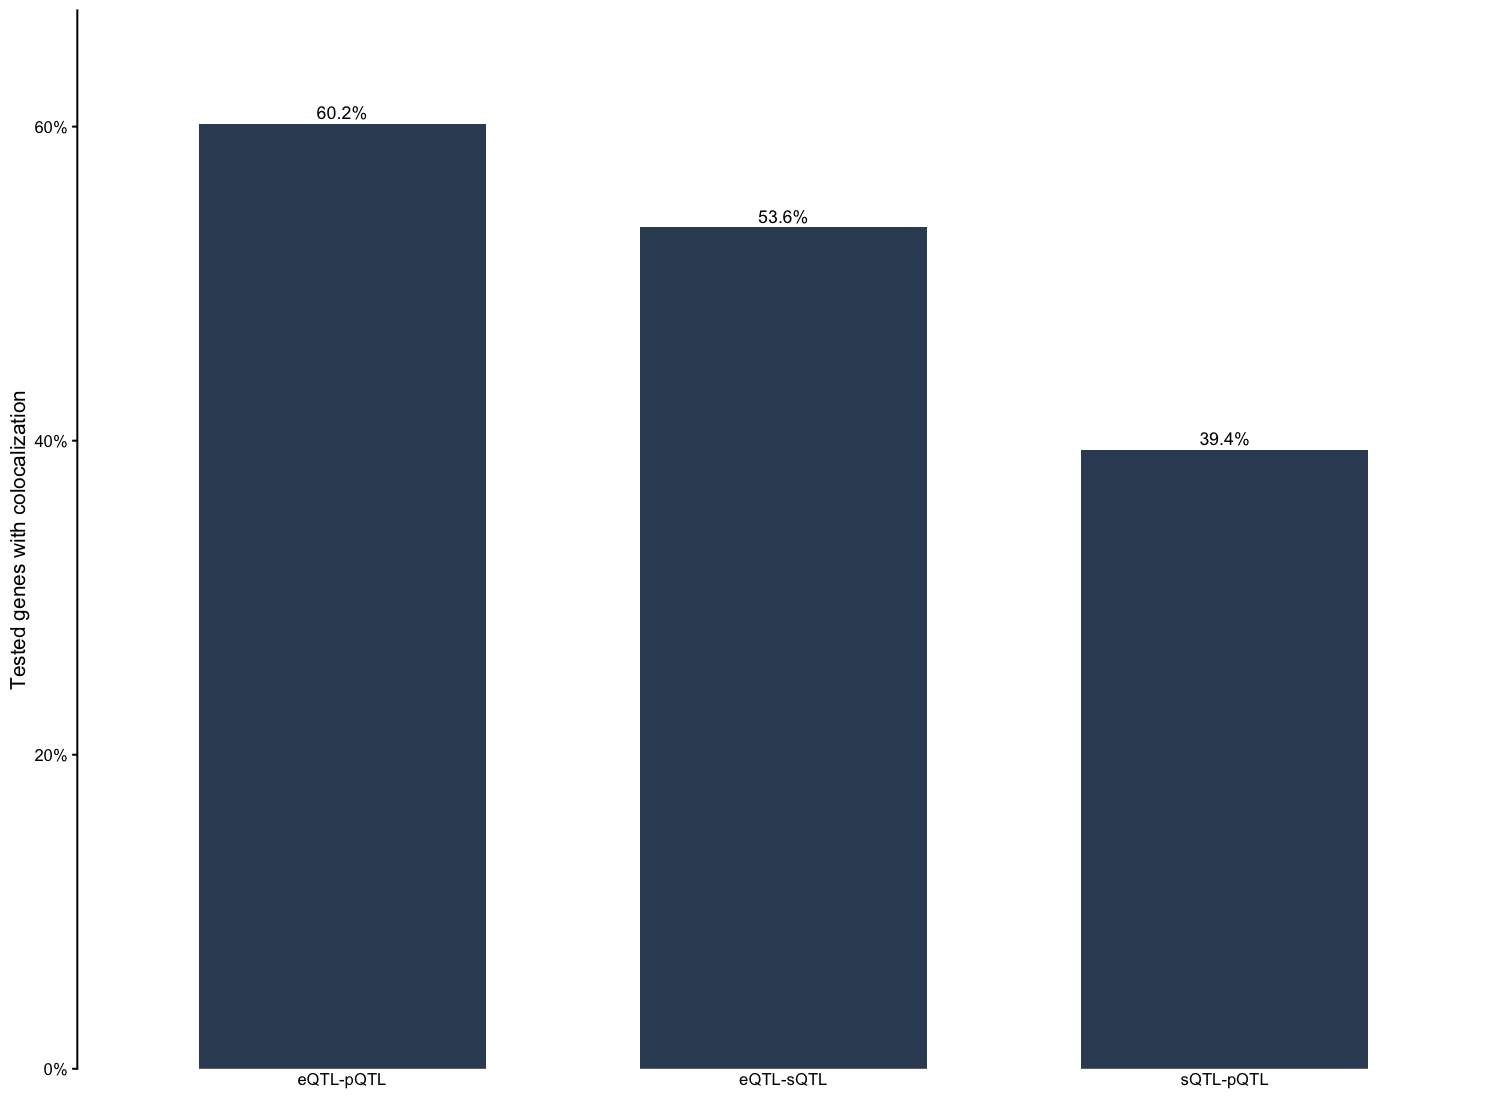

In [3]:
figure <- ggplot(summary, aes(assay_pair, proportion)) +
  geom_col(fill = "#364B63", width = 0.65) +
  geom_text(aes(label = scales::percent(proportion, accuracy = 0.1)), vjust = -0.4, size = 3) +
  scale_y_continuous(labels = scales::label_percent(), expand = expansion(mult = c(0, 0.12))) +
  labs(x = NULL, y = "Tested genes with colocalization") + theme_classic(base_size = 10) +
  theme(axis.line.x = element_blank(), axis.ticks.x = element_blank())
print(figure)


## Save aggregate outputs

Save the plot and the numerator and denominator for each assay pair. The figure has no new hypothesis test or confidence interval.


In [4]:
save_plot(figure, "supplements/S21", 150, 100)
readr::write_tsv(summary, output_file("supplements/S21_gene_summary.tsv"))

message("S21 rebuilt from original result tables.")


Export aggregate plot: supplements/S21


S21 rebuilt from original result tables.
